<a href="https://colab.research.google.com/github/seijuro-code/PEMPAR/blob/main/2411513031_Muhammad_Farid_Al_Hafizh_Tugas4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import aiohttp
import asyncio
import statistics
import time

daftar_paket_banyak = [
    "requests", "numpy", "flask", "aiohttp", "pandas", "django",
    "scipy", "matplotlib", "pillow", "sqlalchemy", "pytest", "fastapi",
    "pydantic", "beautifulsoup4", "jinja2", "click", "tqdm", "scikit-learn",
    "seaborn", "httpx", "celery", "redis", "boto3", "cryptography",
]
print("Jumlah paket:", len(daftar_paket_banyak))


async def ambil_metadata_paket(session, nama_paket):
    url = f"https://pypi.org/pypi/{nama_paket}/json"
    async with session.get(url) as response:
        data = await response.json()
    info = data["info"]
    return {"nama": info["name"], "versi": info["version"]}


async def ambil_dengan_batas(session, nama_paket, semaphore):
    async with semaphore:  # hanya N coroutine yang boleh masuk bersamaan
        return await ambil_metadata_paket(session, nama_paket)


async def ukur_sekali(batas):
    semaphore = asyncio.Semaphore(batas)
    timeout = aiohttp.ClientTimeout(total=60)
    start = time.perf_counter()
    async with aiohttp.ClientSession(timeout=timeout) as session:
        hasil = await asyncio.gather(
            *[ambil_dengan_batas(session, p, semaphore) for p in daftar_paket_banyak]
        )
    waktu = time.perf_counter() - start
    assert len(hasil) == len(daftar_paket_banyak)
    return waktu


async def ukur(batas, ulangan=3):
    return statistics.median([await ukur_sekali(batas) for _ in range(ulangan)])


BATAS_UJI = [1, 3, 5, 10, 20]

await ukur_sekali(5)  # warm-up (tidak dihitung)

waktu_per_batas = {}
for b in BATAS_UJI:
    waktu_per_batas[b] = await ukur(b)
    print(f"BATAS_KONKURENSI = {b:>2} -> waktu (median 3x): {waktu_per_batas[b]:.2f} detik")

Jumlah paket: 24
BATAS_KONKURENSI =  1 -> waktu (median 3x): 2.89 detik
BATAS_KONKURENSI =  3 -> waktu (median 3x): 1.55 detik
BATAS_KONKURENSI =  5 -> waktu (median 3x): 0.98 detik
BATAS_KONKURENSI = 10 -> waktu (median 3x): 0.90 detik
BATAS_KONKURENSI = 20 -> waktu (median 3x): 0.85 detik


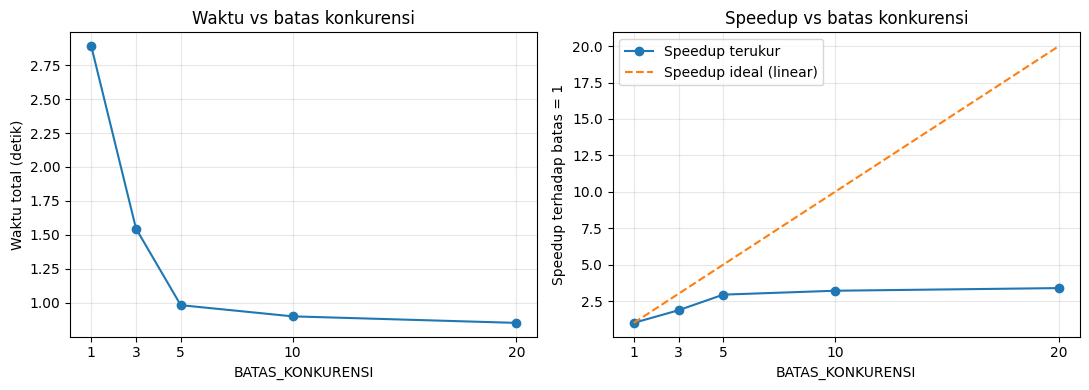

Batas  Waktu (s)  Speedup    Perbaikan vs sebelumnya  p (Amdahl)
    1       2.89     1.00                          -           -
    3       1.55     1.87                        46%        0.70
    5       0.98     2.94                        36%        0.82
   10       0.90     3.21                         8%        0.76
   20       0.85     3.39                         5%        0.74

Perbaikan pertama yang < 10% terjadi saat batas naik ke 10.


In [2]:
import matplotlib.pyplot as plt

batas = BATAS_UJI
waktu = [waktu_per_batas[b] for b in batas]
speedup = [waktu_per_batas[1] / w for w in waktu]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(batas, waktu, marker="o")
ax1.set_xlabel("BATAS_KONKURENSI")
ax1.set_ylabel("Waktu total (detik)")
ax1.set_title("Waktu vs batas konkurensi")
ax1.set_xticks(batas)
ax1.grid(alpha=0.3)

ax2.plot(batas, speedup, marker="o", label="Speedup terukur")
ax2.plot(batas, batas, linestyle="--", label="Speedup ideal (linear)")
ax2.set_xlabel("BATAS_KONKURENSI")
ax2.set_ylabel("Speedup terhadap batas = 1")
ax2.set_title("Speedup vs batas konkurensi")
ax2.set_xticks(batas)
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"{'Batas':>5} {'Waktu (s)':>10} {'Speedup':>8} {'Perbaikan vs sebelumnya':>26} {'p (Amdahl)':>11}")
sebelumnya = None
titik_menurun = None
for b, w, s in zip(batas, waktu, speedup):
    if sebelumnya is None:
        perbaikan, p_txt = "-", "-"
    else:
        perbaikan_nilai = (sebelumnya - w) / sebelumnya * 100
        perbaikan = f"{perbaikan_nilai:.0f}%"
        p = (1 - 1 / s) / (1 - 1 / b)  # dari S = 1 / ((1-p) + p/n)
        p_txt = f"{p:.2f}"
        if titik_menurun is None and perbaikan_nilai < 10:
            titik_menurun = b
    print(f"{b:>5} {w:>10.2f} {s:>8.2f} {perbaikan:>26} {p_txt:>11}")
    sebelumnya = w

print()
if titik_menurun:
    print(f"Perbaikan pertama yang < 10% terjadi saat batas naik ke {titik_menurun}.")
else:
    print("Tidak ada langkah dengan perbaikan < 10% pada data ini.")

**Analisa Nomor 1**
1. Pola waktu: dari BATAS = 1 ke BATAS = 3 waktu turun [ISI]%, tetapi dari 10 ke 20 hanya turun [ISI]%.
Titik manfaat mulai sangat kecil: sekitar BATAS = [ISI].
2. Bagian yang tidak ikut mengecil saat batas dinaikkan (bagian serial): pembuatan ClientSession dan handshake TLS,
 antrean DNS, overhead event loop saat menjadwalkan 24 coroutine, serta waktu tunggu terlama dari satu request yang paling lambat
  (waktu total >= request terlama).
3. Kesimpulan: untuk 24 request, batas sekitar [ISI] sudah cukup;
 angka di atasnya hanya menambah beban tanpa manfaat berarti (diminishing returns).

In [3]:
import asyncio
import time


async def pengukur(durasi=1.5, interval=0.1):
    waktu = []
    mulai = time.perf_counter()
    while time.perf_counter() - mulai < durasi:
        waktu.append(time.perf_counter())
        await asyncio.sleep(interval)
    return waktu


async def tugas_asyncio_sleep():
    await asyncio.sleep(0.5)  # non-blocking: event loop bebas pindah ke coroutine lain


async def tugas_time_sleep():
    time.sleep(0.5)  # BLOCKING: menahan seluruh event loop


async def tugas_cpu_bound(n=58500):
    hasil = 1
    for i in range(1, n + 1):  # tidak ada await -> tidak pernah menyerahkan giliran
        hasil *= i
    return hasil.bit_length()  # (str(hasil) akan error: batas konversi int besar di Python 3.11+)


# Ukur dulu berapa lama tugas CPU-bound berjalan sendirian
t0 = time.perf_counter()
await tugas_cpu_bound()
print(f"Durasi tugas_cpu_bound sendirian: {time.perf_counter() - t0:.2f} detik")

Durasi tugas_cpu_bound sendirian: 1.92 detik


In [8]:
def laporan(nama, waktu_tick):
    gap = [(b - a) * 1000 for a, b in zip(waktu_tick, waktu_tick[1:])]
    max_gap_str = f"{max(gap):7.0f} ms" if gap else "      N/A ms"
    print(f"{nama:<34} tick={len(waktu_tick):>2}   gap maksimum = {max_gap_str}   (ideal ~100 ms)")


async def skenario(nama, *tugas):
    hasil = await asyncio.gather(pengukur(), *[t() for t in tugas])
    laporan(nama, hasil[0])


print("=== Tiap penguji dijalankan terpisah bersama pengukur ===")
await skenario("Pengukur saja (kontrol)")
await skenario("+ asyncio.sleep(0.5)", tugas_asyncio_sleep)
await skenario("+ time.sleep(0.5)", tugas_time_sleep)
await skenario("+ CPU-bound (faktorial)", tugas_cpu_bound)

print()
print("=== Ketiganya sekaligus + 1 pengukur (sesuai soal) ===")
await skenario("Semua penguji + pengukur", tugas_asyncio_sleep, tugas_time_sleep, tugas_cpu_bound)

=== Tiap penguji dijalankan terpisah bersama pengukur ===
Pengukur saja (kontrol)            tick=15   gap maksimum =     101 ms   (ideal ~100 ms)
+ asyncio.sleep(0.5)               tick=15   gap maksimum =     101 ms   (ideal ~100 ms)
+ time.sleep(0.5)                  tick=11   gap maksimum =     500 ms   (ideal ~100 ms)
+ CPU-bound (faktorial)            tick= 1   gap maksimum =       N/A ms   (ideal ~100 ms)

=== Ketiganya sekaligus + 1 pengukur (sesuai soal) ===
Semua penguji + pengukur           tick= 1   gap maksimum =       N/A ms   (ideal ~100 ms)


Analisa Nomor 2

Perbedaan halus: time.sleep() menganggur (CPU bebas, tapi event loop tetap terblokir), sedangkan CPU-bound benar-benar memakai CPU. Dampaknya terhadap event loop sama, tetapi solusinya berbeda:

blocking I/O → pakai versi async (asyncio.sleep, aiohttp) atau await asyncio.to_thread(...);
CPU-bound → loop.run_in_executor() dengan ProcessPoolExecutor (atau multiprocessing), seperti disinggung di bagian 4 materi.
Pada skenario gabungan, gap maksimum sekitar jumlah durasi blocking (time.sleep + CPU-bound), karena keduanya berjalan berurutan di satu thread dan tidak bisa saling tumpang tindih.

In [6]:
import asyncio
import itertools
import random

random.seed(7)  # agar hasil bisa direproduksi

JUMLAH_CONSUMER = 3
JUMLAH_ITEM = 12
PRIORITAS_SELESAI = 99

urutan_mulai = []  # mencatat (prioritas, item) saat mulai diproses


async def producer(queue, jumlah_item):
    nomor = itertools.count()
    for i in range(jumlah_item):
        prioritas = random.randint(1, 3)  # 1 = paling penting
        await queue.put((prioritas, next(nomor), f"item-{i}"))
        print(f"  [Producer] menghasilkan: item-{i} (prioritas {prioritas})")
    for _ in range(JUMLAH_CONSUMER):  # sinyal selesai, SELALU paling akhir
        await queue.put((PRIORITAS_SELESAI, next(nomor), None))


async def consumer(queue, nama):
    while True:
        prioritas, _, item = await queue.get()
        if item is None:
            queue.task_done()
            break
        urutan_mulai.append((prioritas, item))
        print(f"  [{nama}] mulai memproses: {item} (prioritas {prioritas})")
        await asyncio.sleep(random.uniform(0.05, 0.1))  # simulasi pemrosesan
        queue.task_done()


queue = asyncio.PriorityQueue()

await asyncio.gather(
    producer(queue, JUMLAH_ITEM),
    *[consumer(queue, f"Consumer-{i}") for i in range(JUMLAH_CONSUMER)],
)

print()
print("Urutan mulai diproses (prioritas):", [p for p, _ in urutan_mulai])
assert [p for p, _ in urutan_mulai] == sorted(p for p, _ in urutan_mulai), "Urutan prioritas dilanggar!"
print("Terverifikasi: item berprioritas lebih kecil selalu dimulai lebih dulu.")

  [Producer] menghasilkan: item-0 (prioritas 2)
  [Producer] menghasilkan: item-1 (prioritas 1)
  [Producer] menghasilkan: item-2 (prioritas 2)
  [Producer] menghasilkan: item-3 (prioritas 3)
  [Producer] menghasilkan: item-4 (prioritas 1)
  [Producer] menghasilkan: item-5 (prioritas 1)
  [Producer] menghasilkan: item-6 (prioritas 3)
  [Producer] menghasilkan: item-7 (prioritas 1)
  [Producer] menghasilkan: item-8 (prioritas 2)
  [Producer] menghasilkan: item-9 (prioritas 3)
  [Producer] menghasilkan: item-10 (prioritas 1)
  [Producer] menghasilkan: item-11 (prioritas 3)
  [Consumer-0] mulai memproses: item-1 (prioritas 1)
  [Consumer-1] mulai memproses: item-4 (prioritas 1)
  [Consumer-2] mulai memproses: item-5 (prioritas 1)
  [Consumer-1] mulai memproses: item-7 (prioritas 1)
  [Consumer-0] mulai memproses: item-10 (prioritas 1)
  [Consumer-2] mulai memproses: item-0 (prioritas 2)
  [Consumer-1] mulai memproses: item-2 (prioritas 2)
  [Consumer-2] mulai memproses: item-8 (prioritas 

**Analisa soal 3**
1. Pada output, semua item berprioritas 1 dimulai lebih dulu, disusul 2, lalu 3, walaupun item-itemnya dihasilkan dalam urutan acak. Ini diverifikasi otomatis oleh assert di akhir sel.
2. Dalam satu tingkat prioritas yang sama, urutan mengikuti nomor_urut (FIFO) berkat tie-breaker.
3. Dengan 3 consumer, tiga item pertama dimulai hampir bersamaan, tetapi tetap diambil dari antrean dalam urutan prioritas.


**Soal 4**

Untuk kasus I/O-bound, threading paling mudah dimulai, tetapi asyncio paling mudah dikendalikan. Dengan threading, kode yang sudah ada hampir tidak berubah: cukup bungkus ke ThreadPoolExecutor. Kelemahannya, saya harus waspada race condition dan memakai Lock. multiprocessing terasa paling berat: data harus diserialisasi antar proses dan ada biaya memulai proses, padahal untuk I/O-bound manfaatnya tidak sepadan. asyncio awalnya membingungkan karena harus memahami coroutine, await, dan event loop. Di Latihan 2, satu time.sleep() saja membuat semua coroutine ikut macet. Namun setelah paham, pola gather() + Semaphore terasa rapi, hasilnya mudah diprediksi karena perpindahan giliran hanya terjadi di await, dan skalanya jauh lebih besar.